# From Part 1 Notebook

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os
import os.path as op

sys.path.append(op.abspath(""))  

# Load FSL inside Neurodesk (as in the labs)
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.list()

from utils import loadFSL          # utils.py copied from labs 
loadFSL()
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"   # every FSL output as .nii.gz

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from nilearn import plotting, image

from helpers import (find_one, check_tools, run, needs, describe,
                     center_of_mass_world, tissue_volumes, spatial_corr, save_fig)

check_tools("fslreorient2std", "bet", "fast", "flirt", "fnirt", "applywarp")

FSLDIR = /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18/
All tools found: fslreorient2std, bet, fast, flirt, fnirt, applywarp


In [3]:
FORCE = False   # True = recompute every step even if its outputs already exist
ANAT_KW = dict(draw_cross=False, colorbar=False)   # common style for brain figures

PROJECT_ROOT = op.abspath("")      
DATA_DIR = op.join(PROJECT_ROOT, "data")
ANAT_DIR = op.join(PROJECT_ROOT, "derivatives", "anat")
FUNC_DIR = op.join(PROJECT_ROOT, "derivatives", "func")
FIG_DIR  = op.join(PROJECT_ROOT, "figures")
for d in (ANAT_DIR, FUNC_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# Raw data (searched recursively)
T1_RAW   = find_one(DATA_DIR, "T1w.nii.gz")
FMRI_RAW = find_one(DATA_DIR, "tfMRI_LANGUAGE_LR.nii.gz")
EVENTS   = find_one(DATA_DIR, "tfMRI_LANGUAGE_LR_task_onsets.csv")

# MNI152 templates shipped with FSL
STD = op.join(os.environ["FSLDIR"], "data", "standard")
MNI_1MM            = op.join(STD, "MNI152_T1_1mm.nii.gz")
MNI_1MM_BRAIN      = op.join(STD, "MNI152_T1_1mm_brain.nii.gz")
MNI_1MM_BRAIN_MASK = op.join(STD, "MNI152_T1_1mm_brain_mask.nii.gz")
MNI_2MM            = op.join(STD, "MNI152_T1_2mm.nii.gz")
MNI_2MM_BRAIN      = op.join(STD, "MNI152_T1_2mm_brain.nii.gz")
MNI_2MM_MASK_DIL   = op.join(STD, "MNI152_T1_2mm_brain_mask_dil.nii.gz")

for p in (T1_RAW, FMRI_RAW, EVENTS):
    print(op.relpath(p, PROJECT_ROOT))

data/T1w.nii.gz
data/tfMRI_LANGUAGE_LR.nii.gz
data/tfMRI_LANGUAGE_LR_task_onsets.csv


In [4]:
for p in (T1_RAW, FMRI_RAW, MNI_1MM):
    describe(p)
    print()

events = pd.read_csv(EVENTS)
events.head(10)

T1w.nii.gz
  shape:       (260, 311, 260)
  voxel size:  (0.7, 0.7, 0.7)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       float32

tfMRI_LANGUAGE_LR.nii.gz
  shape:       (91, 109, 91, 316)
  voxel size:  (2.0, 2.0, 2.0, 0.72)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       float32

MNI152_T1_1mm.nii.gz
  shape:       (182, 218, 182)
  voxel size:  (1.0, 1.0, 1.0)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       int16



,onset,duration,trial_type
0,0.241,28.270,story
1,0.241,20.445,present_story
2,21.192,1.161,question_story
3,25.550,2.961,response_story
4,28.696,0.727,cue
5,30.095,5.667,present_math
6,30.095,12.241,math
7,35.946,3.391,question_math
8,39.371,2.965,response_math
9,42.570,5.453,present_math


# 1.3 General Linear Model
### 1.3.a Building experimental design matrix
Building the experimental design matrix of the GLM from the events file.
Taking into account the motion confounds from the previous preprocessing and the drift that can occur over time with a cosine drift model.

In [5]:
from nilearn.glm.first_level import make_first_level_design_matrix, FirstLevelModel

TR = 0.72
FMRI_SMOOTH  = op.join(FUNC_DIR, "tfMRI_LANGUAGE_LR_mc_smooth.nii.gz")
CONFOUNDS    = op.join(FUNC_DIR, "func_motion_confounds.csv")
motion = pd.read_csv(CONFOUNDS)

# Specification of GLM
fmri_glm = FirstLevelModel(t_r=TR, # repetition time
                           noise_model='ar1', #first level autoregressive noise model
                           standardize=False,
                           hrf_model='spm', #hemodynamic response function
                           drift_model='cosine', #account for drift over time
                           high_pass=.01)

# Fit the model to our design and data
fmri_glm = fmri_glm.fit(FMRI_SMOOTH, events,
                        confounds=motion[['rot_x', 'rot_y','rot_z', 'trans_x', 'trans_y', 'trans_z']]) # motion confounds from funct preprocessing

/opt/conda/lib/python3.13/site-packages/nilearn/glm/first_level/first_level.py:707: UserWarning: Mean values of 0 observed. The data have probably been centered.Scaling might not work as expected
  Y, _ = mean_scaling(Y, self.signal_scaling)


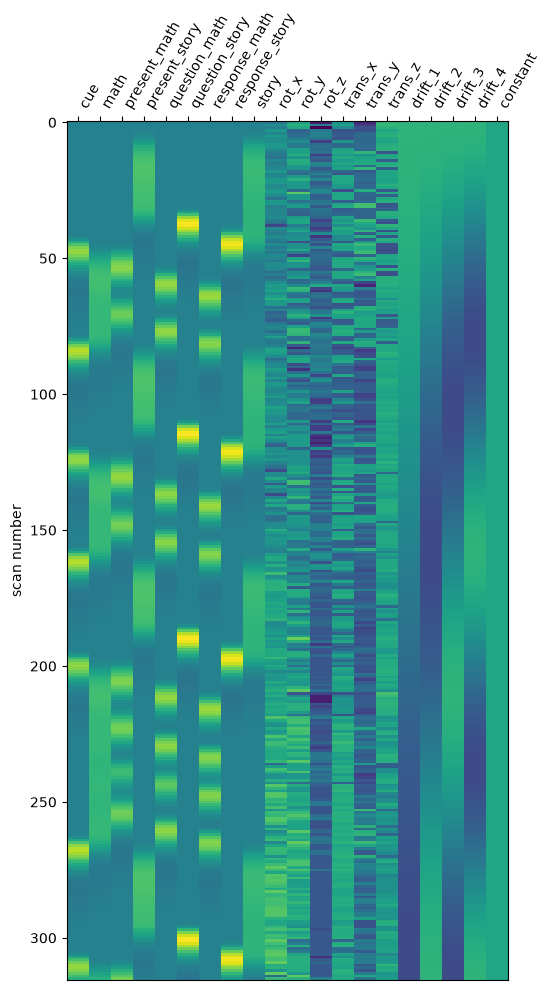

<Figure size 640x480 with 0 Axes>

In [46]:
from nilearn.plotting import plot_design_matrix

design_mat = fmri_glm.design_matrices_[0]
plot_design_matrix(design_mat)
plt.show()
plt.savefig(op.join(GLM_FIG_DIR, "design_matrix.png"), dpi=300, bbox_inches="tight")

### 1.3.b Correlation matrix between regressors
It is necessary to look at the correlation matrix between regressors as highly correlated regressors result in unstable estimation of the bethas. 

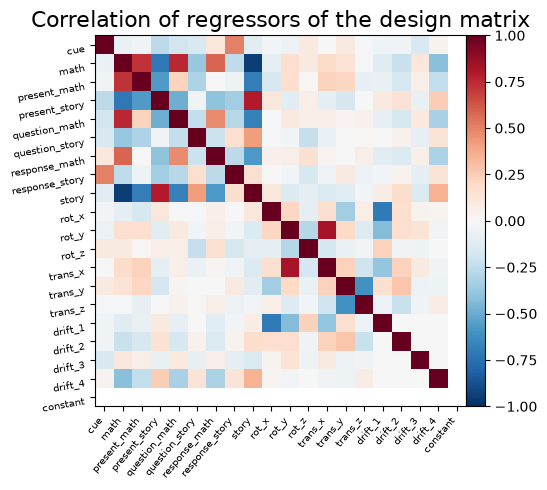

<Figure size 640x480 with 0 Axes>

In [45]:
from nilearn.plotting import plot_matrix
columns = ['cue', 'math','present_math','present_story','question_math','question_story','response_math','response_story', 'story']

corr = design_mat.corr()

plot_matrix(corr,title='Correlation of regressors of the design matrix', labels=list(design_mat.columns),vmin=-1, vmax=1, cmap="RdBu_r")
plt.show()

plt.savefig(op.join(GLM_FIG_DIR, "correlation_regressors.png"), dpi=300, bbox_inches="tight")

The task specific regressors are more correlected amongst themseleves with the "math" regressor positively correlated with math-related regressors and negatively correlated with story-related regressors. The motion regressors are more correlated amongst themselves and have almost no correlation with the task regressors. These results are expected.

### 1.3.c Statistical maps of task-related regressors
In point 1.3.a) we already runned the GLM at **first level**. We have only one single subject, there is no group level with random effects to take into account.

In [10]:
# Task related regressors 
task_reg = ['cue', 'math','present_math','present_story','question_math','question_story','response_math','response_story', 'story']

design_matrix = fmri_glm.design_matrices_[0]

contrasts = {t: np.eye(design_matrix.shape[1])[design_matrix.columns.get_loc(t)] for t in task_reg} # contrast of each task regressor

z_maps = {name: fmri_glm.compute_contrast(vec, output_type="z_score") for name, vec in contrasts.items()}

Due to the multiple voxels we need to correct for multiple statistical tests.

In [19]:
from nilearn.glm import threshold_stats_img
from nilearn.reporting import get_clusters_table

GLM_DIR = op.join(PROJECT_ROOT, "derivatives", "glm")
STAT_DIR = op.join(GLM_DIR, "statistical_maps")
os.makedirs(STAT_DIR, exist_ok=True)

thresholded, thr = {}, {}
for name, z in z_maps.items():
    thresholded[name], thr[name] = threshold_stats_img(z, alpha=0.05, 
                                                       height_control="fdr", cluster_threshold=10) # correction for multiple voxels
    
    # saving each cluster to csv file
    table = get_clusters_table(z, stat_threshold=thr[name], cluster_threshold=10)
    table.to_csv(op.join(STAT_DIR, f"{name}_clusters.csv"), index=False)

/opt/conda/lib/python3.13/site-packages/nilearn/reporting/get_clusters_table.py:104: UserWarning: Attention: At least one of the (sub)peaks falls outside of the cluster body. Identifying the nearest in-cluster voxel.
  warnings.warn(
/tmp/ipykernel_968/3018177299.py:13: UserWarning: Attention: No clusters with stat higher than 4.469237436202735
  table = get_clusters_table(z, stat_threshold=thr[name], cluster_threshold=10)
/opt/conda/lib/python3.13/site-packages/nilearn/reporting/get_clusters_table.py:104: UserWarning: Attention: At least one of the (sub)peaks falls outside of the cluster body. Identifying the nearest in-cluster voxel.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/nilearn/reporting/get_clusters_table.py:104: UserWarning: Attention: At least one of the (sub)peaks falls outside of the cluster body. Identifying the nearest in-cluster voxel.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/nilearn/reporting/get_clusters_table.py:104: UserWarning: Attenti

/opt/conda/lib/python3.13/site-packages/nilearn/plotting/displays/_slicers.py:308: UserWarning: empty mask
  ims = self._map_show(img, type="imshow", threshold=threshold, **kwargs)


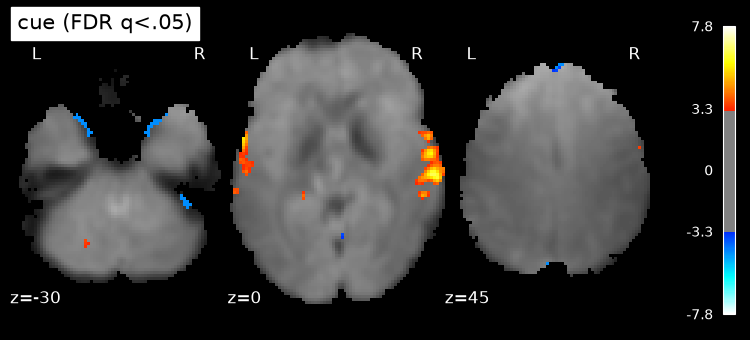

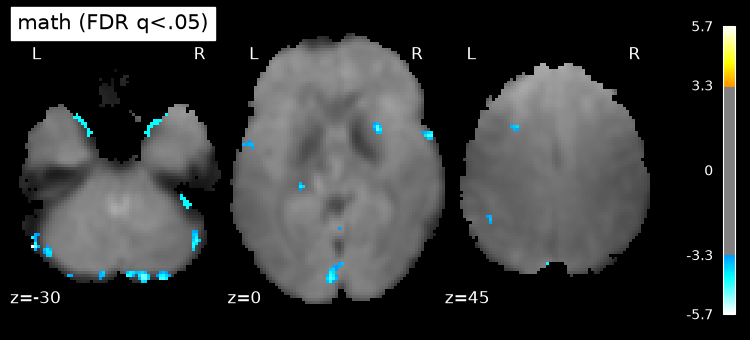

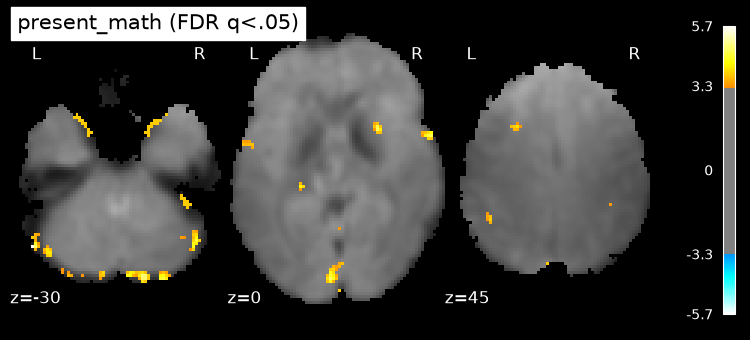

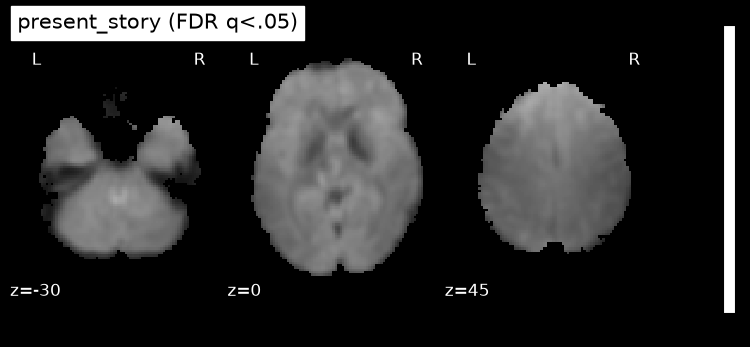

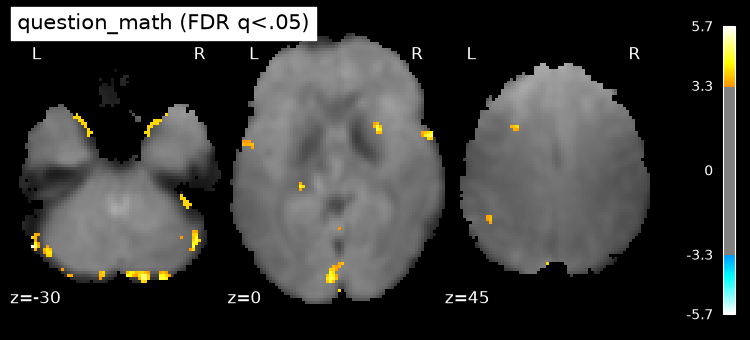

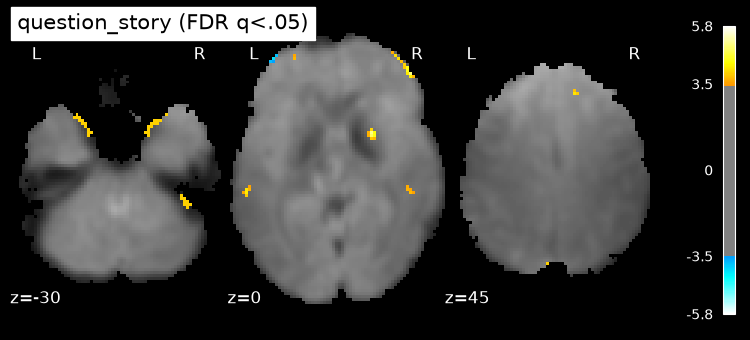

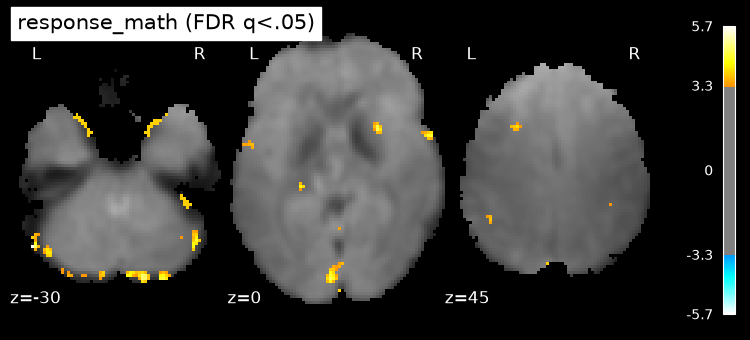

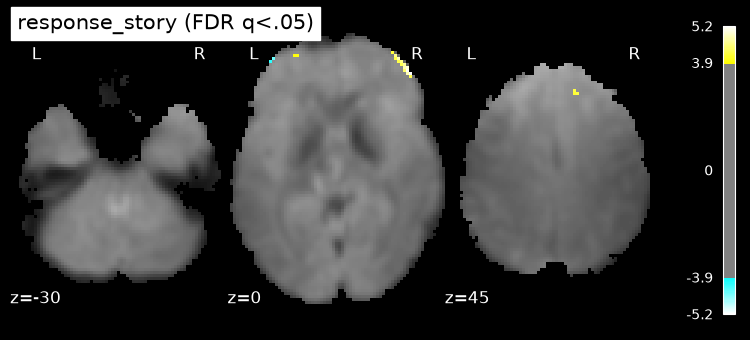

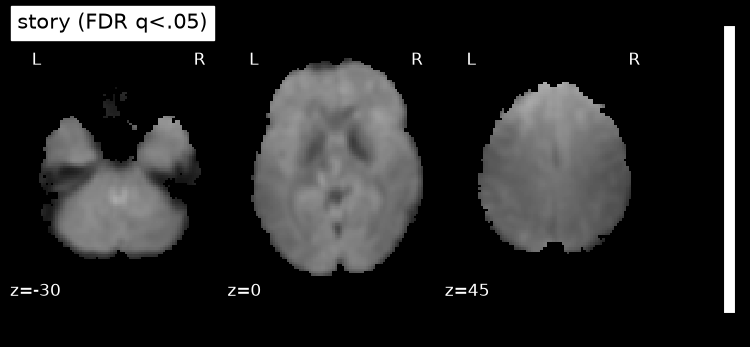

In [22]:
from nilearn import plotting
from nilearn.plotting import plot_stat_map
from nilearn.image import mean_img

GLM_FIG_DIR = op.join(FIG_DIR, 'GLM')
os.makedirs(GLM_FIG_DIR, exist_ok=True)

mean_img_ = mean_img(FMRI_SMOOTH)
cut = [-30,0,45] # change cut for image visualization

for name, img in thresholded.items():
    plotting.plot_stat_map(img, bg_img=mean_img_, threshold=thr[name],
                           display_mode="z", cut_coords=cut,
                           title=f"{name} (FDR q<.05)", colorbar=True)
    # saving images 
    plt.savefig(op.join(GLM_FIG_DIR, f"{name}_zmap.png"), dpi=300, bbox_inches="tight")

### 1.3.d Contrast vector and story-vs-math activation map
We are interested in the difference between story and math events. To investigate the overall differences, we can define a contrast vector with +1 for every language specific regressors and a -1 for every math specific regressors. Every other unrelated regressors (motion counfounds, drifts) are set to 0. We would get :

$$\large c_{story - math} =
\begin{bmatrix}
0 & -1 & -1 & 1 & -1 & 1 & -1 & 1 & 1 &0 &...\end{bmatrix}
\begin{bmatrix}
\vec{\beta_{cue}}\\
\vec{\beta_{math}}\\
\vec{\beta_{present\_math}}\\
\vec{\beta_{present\_story}}\\
\vec{\beta_{question\_math}}\\
\vec{\beta_{question\_story}}\\
\vec{\beta_{response\_math}}\\
\vec{\beta_{response\_story}}\\
\vec{\beta_{story}}\\
\vec{\beta_{rot\_x}}\\
\vec{...}\\
\end{bmatrix}$$

In [38]:
# define story & math regressors
story_reg = ['present_story','question_story','response_story', 'story'] 
math_reg = ['math','present_math','question_math','response_math']

cols = list(design_matrix.columns)

story_vec = np.zeros(len(cols))
for r in story_reg:
    story_vec[cols.index(r)] = 1.0
math_vec = np.zeros(len(cols))
for r in math_reg:
    math_vec[cols.index(r)] = 1.0

story_minus_math = story_vec - math_vec
print('Contrast vector: ',story_minus_math)

Contrast vector:  [ 0. -1. -1.  1. -1.  1. -1.  1.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.]


In [27]:
z_map = fmri_glm.compute_contrast(story_minus_math,
                                  output_type='z_score')

thresholded_sto_min_mat, thr_sto_min_math = threshold_stats_img(z_map, alpha=0.05, 
                                                             height_control="fdr", cluster_threshold=10)
    
# saving to csv file
table = get_clusters_table(z, stat_threshold=thr_sto_min_math, cluster_threshold=10)
table.to_csv(op.join(STAT_DIR, f"story_minus_math_clusters.csv"), index=False)

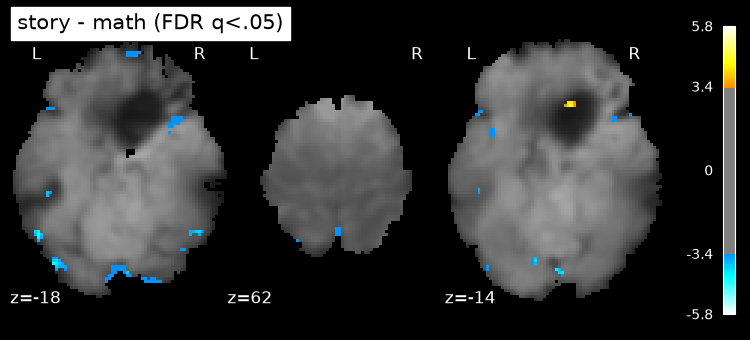

In [31]:
mean_img_ = mean_img(FMRI_SMOOTH)
cut = [20,58,-12] # change cut for images
cut = [-18,62,-14]

plotting.plot_stat_map(thresholded_sto_min_mat, bg_img=mean_img_, threshold=thr_sto_min_math,
                           display_mode="z", cut_coords=cut,
                           title=f"story - math (FDR q<.05)", colorbar=True)
# saving image 
plt.savefig(op.join(GLM_FIG_DIR, f"story_minus_math_zmap_{cut}.png"), dpi=300, bbox_inches="tight")

### 1.3.e Networks more involved in numerical than semantic

In [ ]:
# Here display clusters with yeo17 atlas